In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/npci-online-peer-to-peer-lending/sample_submission.csv
/kaggle/input/npci-online-peer-to-peer-lending/train.csv
/kaggle/input/npci-online-peer-to-peer-lending/test.csv


In [2]:
test = pd.read_csv("../input/npci-online-peer-to-peer-lending/test.csv" )
train= pd.read_csv("../input/npci-online-peer-to-peer-lending/train.csv")

In [3]:
train.head(15)

,loan_number,amount_borrowed,term,borrower_rate,installment,grade,origination_date,listing_title,principal_balance,principal_paid,interest_paid,late_fees_paid,last_payment_date,next_payment_due_date,days_past_due,loan_status_description,data_source
0,71418865,5100,36,0.0916,162.56,B,2016-02-01T00:00,credit_card,1256.87,3843.13,705.95,0.00,2018-06-01T00:00,2018-07-01T00:00,60,CURRENT,'Lending Club'
1,44116029,11775,60,0.1786,298.12,D,2015-03-01T00:00,debt_consolidation,0.00,2356.98,2687.69,0.00,2016-09-01T00:00,2016-10-01T00:00,698,CHARGEOFF,'Lending Club'
2,30245478,20000,36,0.0839,630.34,A,2014-10-01T00:00,debt_consolidation,0.00,20000.00,2668.60,0.00,2017-10-01T00:00,2017-11-01T00:00,0,COMPLETED,'Lending Club'
3,71673111,6000,36,0.0649,183.87,A,2016-02-01T00:00,debt_consolidation,0.00,6000.00,346.34,0.00,2017-02-01T00:00,2017-03-01T00:00,0,COMPLETED,'Lending Club'
4,15481006,22500,36,0.0662,690.84,A,2014-05-01T00:00,debt_consolidation,0.00,22500.00,1240.16,0.00,2015-12-01T00:00,2016-01-01T00:00,0,COMPLETED,'Lending Club'
5,43699382,9000,36,0.0692,277.57,A,2015-03-01T00:00,debt_consolidation,0.00,9000.00,798.33,0.00,2016-12-01T00:00,2017-01-01T00:00,0,COMPLETED,'Lending Club'
6,61198166,13275,36,0.0789,415.32,A,2015-10-01T00:00,debt_consolidation,1229.63,12045.37,1654.37,0.00,2018-07-01T00:00,2018-08-01T00:00,29,CURRENT,'Lending Club'
7,72692812,3200,36,0.1199,106.28,C,2016-02-01T00:00,credit_card,0.00,3200.00,84.45,0.00,2016-04-01T00:00,2016-05-01T00:00,0,COMPLETED,'Lending Club'
8,63979695,35000,60,0.2299,986.47,F,2015-11-01T00:00,home_improvement,21815.73,13184.27,17339.45,49.32,2018-06-01T00:00,2018-07-01T00:00,60,CURRENT,'Lending Club'
9,75921617,30000,60,0.0975,633.73,B,2016-03-01T00:00,debt_consolidation,18279.25,11720.75,5389.96,0.00,2018-07-01T00:00,2018-08-01T00:00,29,CURRENT,'Lending Club'


In [4]:
train.shape

(943695, 17)

In [5]:
test.describe()

,loan_number,amount_borrowed,term,borrower_rate,installment,principal_balance,principal_paid,interest_paid,late_fees_paid,days_past_due
count,1.048550e+05,104855.000000,104855.000000,104855.000000,104855.000000,104855.000000,104855.000000,104855.000000,104855.000000,104855.000000
mean,4.189571e+07,15026.915026,43.068962,0.131412,445.750412,1424.560861,11875.081678,2984.569664,1.458061,139.547299
std,2.572055e+07,8527.346174,10.940110,0.045032,248.977935,3602.969571,8117.336581,2980.822487,10.680392,333.948253
min,3.630090e+05,1000.000000,36.000000,0.053200,14.010000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.528054e+07,8400.000000,36.000000,0.097100,265.460000,0.000000,5727.640000,1020.045000,0.000000,0.000000
50%,4.497541e+07,13500.000000,36.000000,0.128800,389.030000,0.000000,10000.000000,1990.880000,0.000000,0.000000
75%,6.524117e+07,20000.000000,60.000000,0.158800,584.685000,0.000000,16000.000000,3887.860000,0.000000,60.000000
max,8.442314e+07,40000.000000,60.000000,0.309900,1451.120000,29119.960000,40000.000000,27360.680000,731.840006,2402.000000


<AxesSubplot:xlabel='loan_number', ylabel='Count'>

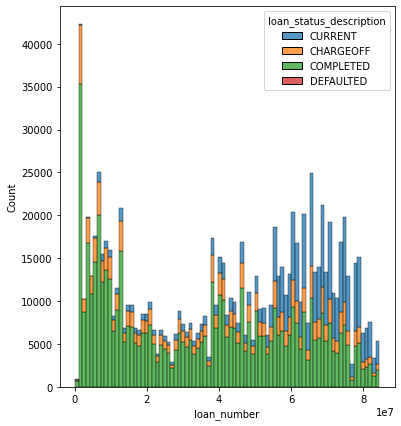

In [6]:
import matplotlib.pyplot as plt
import seaborn as df

plt.figure(figsize=(6,7))
df.histplot(data=train, x="loan_number",hue="loan_status_description",multiple='stack')

In [7]:
test.head

<bound method NDFrame.head of         loan_number  amount_borrowed  term  borrower_rate  installment grade  \
0           1582834            16000    60         0.1522       382.49     C   
1          75679675             4800    36         0.2118       181.29     E   
2           6178775            20000    36         0.1368       680.45     C   
3          55667318            15000    36         0.1757       539.06     D   
4          60315522             8000    36         0.1399       273.39     C   
...             ...              ...   ...            ...          ...   ...   
104850     56050781            18000    60         0.1757       452.89     D   
104851     43769718            20000    36         0.0917       637.58     B   
104852     64231414             5200    36         0.1099       170.22     B   
104853     59462626            20000    36         0.1699       712.96     D   
104854     38455988            16000    36         0.1269       536.72     C   

        o

<AxesSubplot:xlabel='loan_status_description', ylabel='count'>

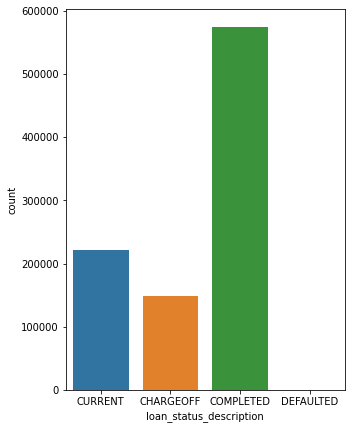

In [8]:
fig,ax = plt.subplots(figsize=(5,7))
df.countplot(x='loan_status_description',data=train)

In [21]:
print(train["loan_status_description"].value_counts())

# CURRENT loans are still ongoing, we don't yet know their final outcome,
# so only resolved loans (paid off or charged off) can be used to train a
# real risk model. Including CURRENT would mislabel loans that might still
# default later.
resolved = train[train["loan_status_description"].isin(["COMPLETED", "CHARGEOFF"])].copy()
resolved["bad_loan"] = (resolved["loan_status_description"] == "CHARGEOFF").astype(int)

print(resolved.shape)
print(resolved["bad_loan"].value_counts(normalize=True))

COMPLETED    574023
CURRENT      220985
CHARGEOFF    148268
DEFAULTED       419
Name: loan_status_description, dtype: int64
(722291, 18)
0    0.794725
1    0.205275
Name: bad_loan, dtype: float64


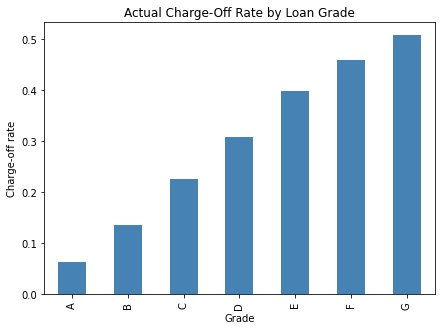

grade
A    0.062945
B    0.135309
C    0.225995
D    0.308152
E    0.397909
F    0.458779
G    0.508341
Name: bad_loan, dtype: float64


In [22]:
grade_order = sorted(resolved["grade"].unique())
grade_default_rate = resolved.groupby("grade")["bad_loan"].mean().reindex(grade_order)

grade_default_rate.plot(kind="bar", figsize=(7,5), color="steelblue")
plt.title("Actual Charge-Off Rate by Loan Grade")
plt.ylabel("Charge-off rate")
plt.xlabel("Grade")
plt.show()

print(grade_default_rate)

In [23]:
# Only features known at the moment the loan is issued.
# Excludes principal_balance, principal_paid, interest_paid, late_fees_paid,
# days_past_due, last_payment_date, next_payment_due_date entirely,
# since those are consequences of the loan's performance, not causes.
features = resolved[["amount_borrowed", "term", "borrower_rate", "installment", "grade", "listing_title"]]
X = pd.get_dummies(features)
y = resolved["bad_loan"]

print(X.shape)

(722291, 25)


In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

log_reg = LogisticRegression(max_iter=1000, class_weight="balanced")
log_reg.fit(X_train_scaled, y_train)
log_reg_preds = log_reg.predict(X_val_scaled)
log_reg_probs = log_reg.predict_proba(X_val_scaled)[:, 1]

rf = RandomForestClassifier(n_estimators=300, max_depth=10, class_weight="balanced", random_state=42)
rf.fit(X_train, y_train)
rf_preds = rf.predict(X_val)
rf_probs = rf.predict_proba(X_val)[:, 1]

In [25]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

for name, preds, probs in [("Logistic Regression", log_reg_preds, log_reg_probs),
                            ("Random Forest", rf_preds, rf_probs)]:
    print(f"--- {name} ---")
    print(classification_report(y_val, preds))
    print("ROC-AUC:", round(roc_auc_score(y_val, probs), 4))
    print(confusion_matrix(y_val, preds))
    print()

--- Logistic Regression ---
              precision    recall  f1-score   support

           0       0.87      0.64      0.74    114805
           1       0.31      0.64      0.42     29654

    accuracy                           0.64    144459
   macro avg       0.59      0.64      0.58    144459
weighted avg       0.76      0.64      0.67    144459

ROC-AUC: 0.6929
[[73041 41764]
 [10760 18894]]

--- Random Forest ---
              precision    recall  f1-score   support

           0       0.88      0.60      0.72    114805
           1       0.31      0.68      0.43     29654

    accuracy                           0.62    144459
   macro avg       0.59      0.64      0.57    144459
weighted avg       0.76      0.62      0.66    144459

ROC-AUC: 0.6987
[[69372 45433]
 [ 9380 20274]]



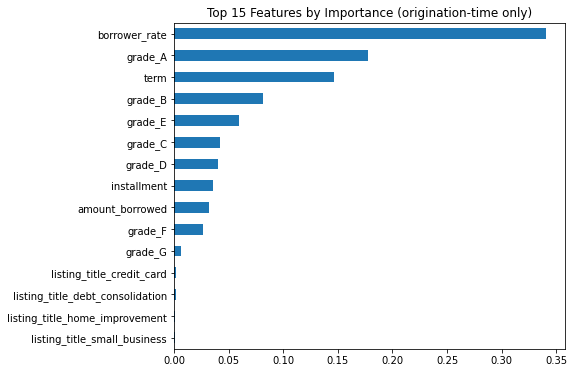

In [26]:
importances = pd.Series(rf.feature_importances_, index=X_train.columns)
importances.sort_values(ascending=False).head(15).plot(kind="barh", figsize=(7,6))
plt.gca().invert_yaxis()
plt.title("Top 15 Features by Importance (origination-time only)")
plt.show()